<a href="https://colab.research.google.com/github/hyo-yeon-lee/MCNB-Introduction-to-Programming/blob/main/5_image_processing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Image processing in python

Python can do load images and manipulate them in various ways. This is really important in cagnitive neuroscience, where many of our paradigms involve images.

# Practical 1: Image processing

Let's do some image processing.

We'll use some images I shared on blackboard. Here are steps to upload them here.

1. Download the imgs.zip file from blackboard.
2. <---- Click the folder icon to the left of this colab window.
3. Drag and drop the imgs.zip file in there
4. Run the following cell to unzip the file so you can use it.

In [17]:
import zipfile

zip_path = "/imgs.zip"   # ← replace with your uploaded filename
extract_to = "."             # or choose a folder, e.g. "data/"

with zipfile.ZipFile(zip_path, 'r') as z:
    z.extractall(extract_to)

Now, let's import the librairies we will need:

In [14]:
import numpy as np
from PIL import Image, ImageFilter
import matplotlib.pyplot as plt
import os

In './imgs' directory, there are two sub-directories: 'cameleon' and 'goat'.
Each contains 5 images.
1.1.load all images of cameleons in a cam_imgs list and display them in a subplot.
1.2.load all images of goats in a goat_imgs list and display them in a subplot.

In [21]:
ls

drive/  imgs/  __MACOSX/  sample_data/


In [22]:
pwd

'/content'

['cameleon.jpg', 'cam1.jpg', 'tinycam.jpg', 'came00.jpg', 'weirdcam.jpg']


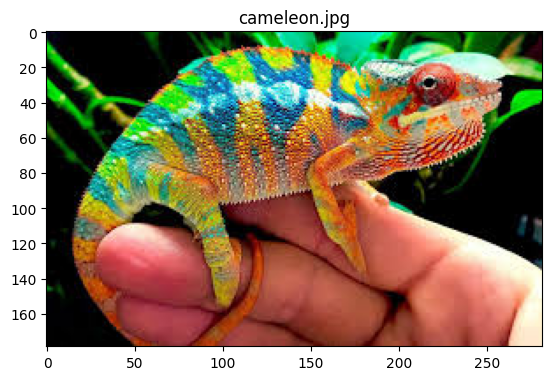

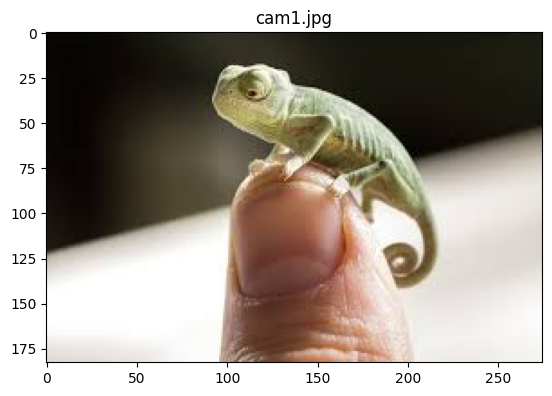

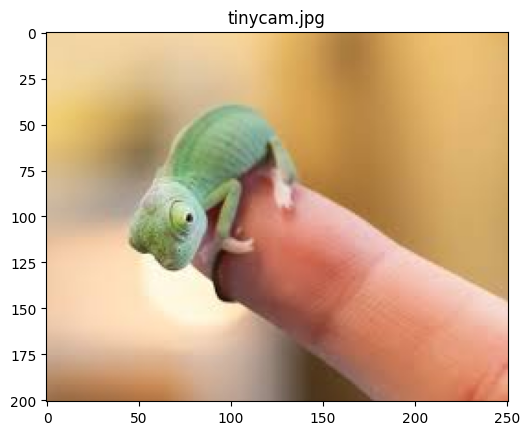

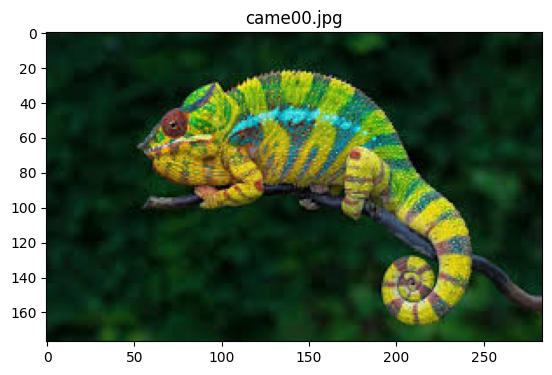

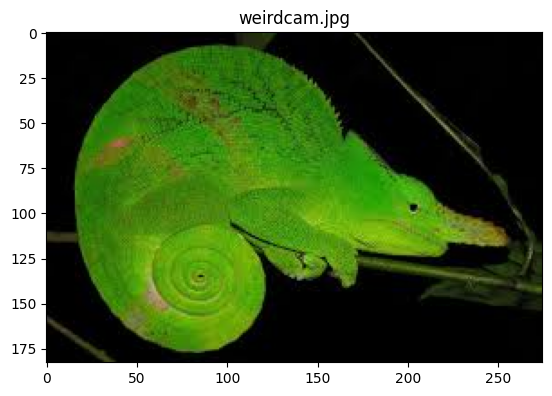

['goat.jpg', 'g0.jpg', 'goat22.jpg', 'goaaaaat.jpg', 'twogoats.jpg']


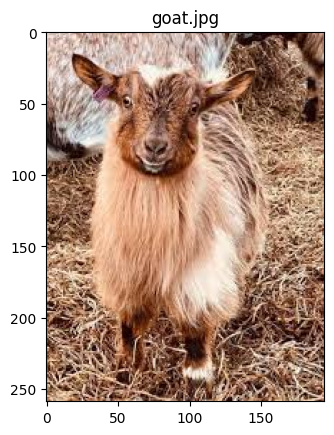

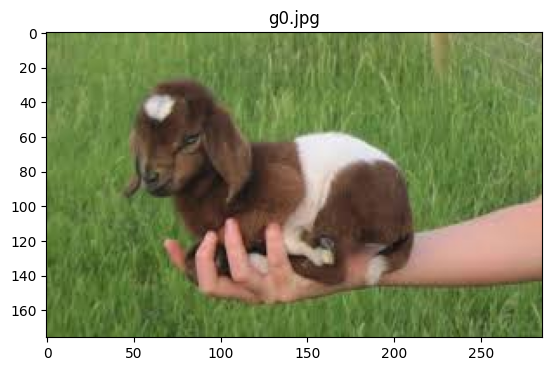

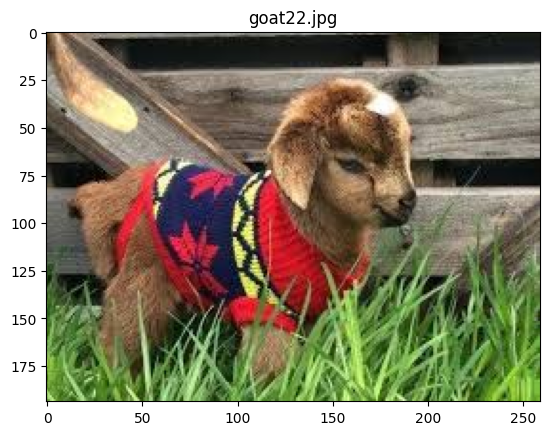

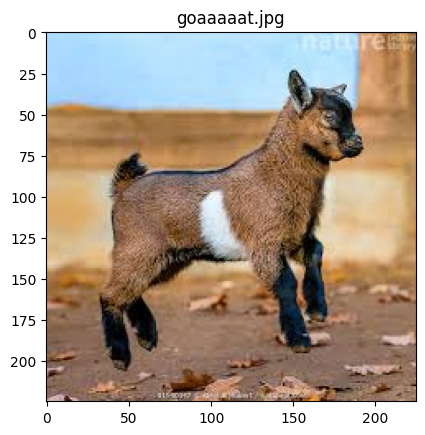

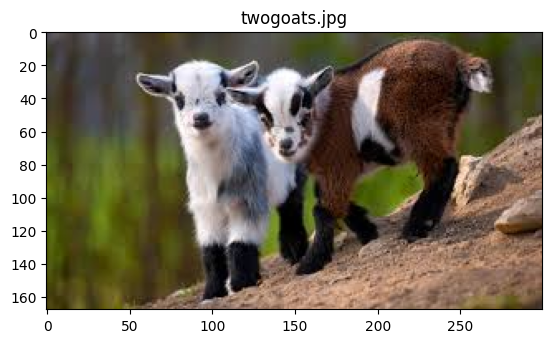

In [53]:
# TODO: 1.1. Load all images of cameleons in a cam_imgs list and display them in a subplot.
cam_img_paths = os.listdir('./imgs/cameleon')
print(cam_img_paths)

cam_imgs = [plt.imread(f"./imgs/cameleon/{img}") for img in cam_img_paths]
for i in range(len(cam_img_paths)):
  plt.imshow(cam_imgs[i])
  plt.title(cam_img_paths[i])
  plt.show()
  plt.close()


# TODO: 1.2. Load all images of goats in a goat_imgs list and display them in a subplot.
goat_img_paths = os.listdir('./imgs/goat')
print(goat_img_paths)

goat_imgs = [plt.imread(f"./imgs/goat/{img}") for img in goat_img_paths]
for i in range(len(goat_img_paths)):
  plt.imshow(goat_imgs[i])
  plt.title(goat_img_paths[i])
  plt.show()
  plt.close()


Now, we will simulate a small experiment.
For each trial, we will present a random image, and apply a random filter to it.

To this end, we will:
- Pick a random category ('cameleon' or 'goat')
- Pick a random image ID (i.e., a number between 0 and the number of cameleon/goat images we have)
  - For example, if category = 'goat' and img_id = 2, we will present goat_imgs[2]
- Pick a random filter to apply from 'BLUR', 'CONTOUR', or 'FIND_EDGES'

We will store all relevant info about which images we presented in a expt_dict:
- We will create a key with an empty "subdict" for each trial: e.g. expt_dict['trial_n'] = {}
- We will store the image category in expt_dict['trial_n']['category']
- We will store the ID of the image in expt_dict['trial_n']['img_id']
- We will store the filter applied in expt_dict['trial_n']['filter']

The number of trials:  7
Category for this trial:  cameleon
Image ID for this trial:  2
Filter for this trial:  BLUR


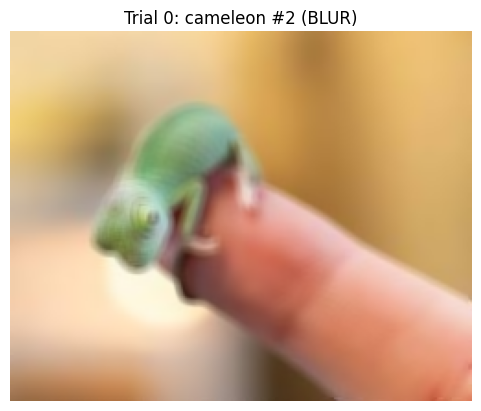

Category for this trial:  goat
Image ID for this trial:  1
Filter for this trial:  FIND_EDGES


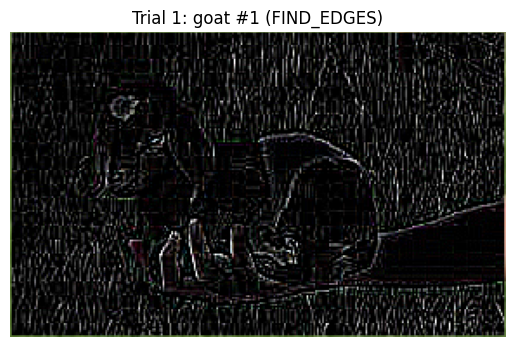

Category for this trial:  cameleon
Image ID for this trial:  0
Filter for this trial:  FIND_EDGES


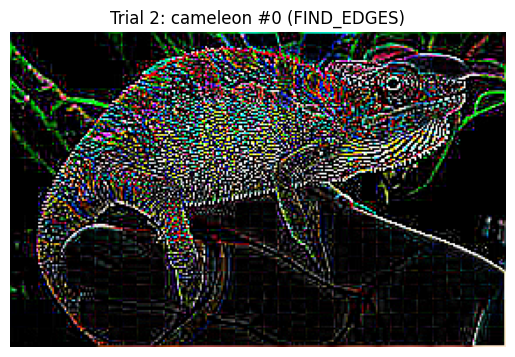

Category for this trial:  goat
Image ID for this trial:  3
Filter for this trial:  BLUR


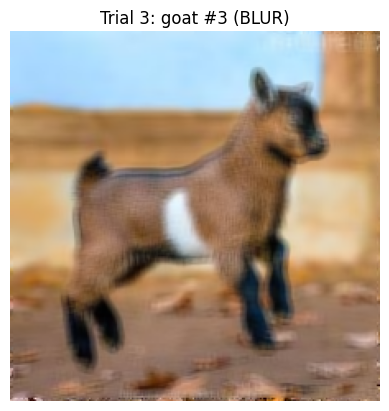

Category for this trial:  goat
Image ID for this trial:  4
Filter for this trial:  CONTOUR


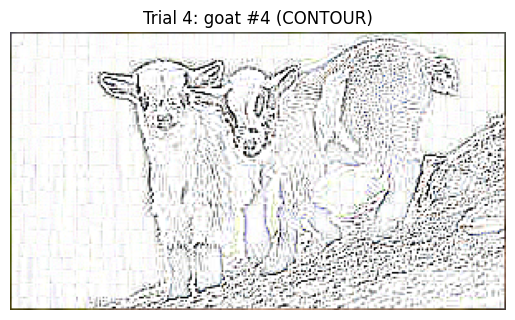

Category for this trial:  cameleon
Image ID for this trial:  3
Filter for this trial:  FIND_EDGES


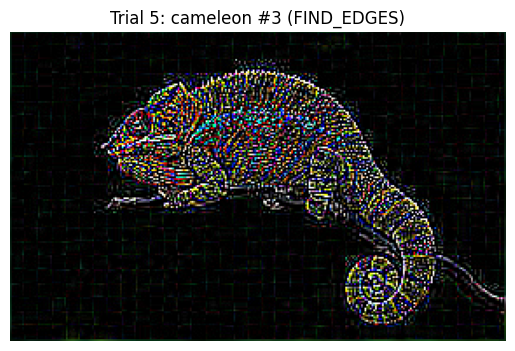

Category for this trial:  cameleon
Image ID for this trial:  1
Filter for this trial:  BLUR


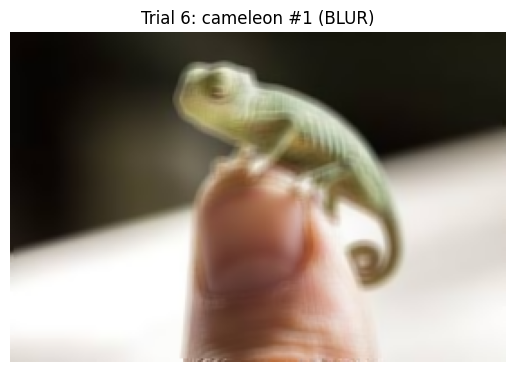

{'trial_0': {'category': np.str_('cameleon'), 'img_id': 2, 'filter': np.str_('BLUR')}, 'trial_1': {'category': np.str_('goat'), 'img_id': 1, 'filter': np.str_('FIND_EDGES')}, 'trial_2': {'category': np.str_('cameleon'), 'img_id': 0, 'filter': np.str_('FIND_EDGES')}, 'trial_3': {'category': np.str_('goat'), 'img_id': 3, 'filter': np.str_('BLUR')}, 'trial_4': {'category': np.str_('goat'), 'img_id': 4, 'filter': np.str_('CONTOUR')}, 'trial_5': {'category': np.str_('cameleon'), 'img_id': 3, 'filter': np.str_('FIND_EDGES')}, 'trial_6': {'category': np.str_('cameleon'), 'img_id': 1, 'filter': np.str_('BLUR')}}


In [81]:

expt_dict = {}
categories = ['goat', 'cameleon']
filters = ['BLUR', 'CONTOUR', 'FIND_EDGES']

n_trials = np.random.randint(5, 10)
print("The number of trials: ", n_trials)

for i in range(n_trials):
    dum_cat = np.random.choice(categories)
    print("Category for this trial: ", dum_cat)

    imgs = cam_imgs if dum_cat == 'cameleon' else goat_imgs

    dum_id = np.random.randint(len(imgs))
    print("Image ID for this trial: ", dum_id)

    dum_filter = np.random.choice(filters)
    print("Filter for this trial: ", dum_filter)

    expt_dict[f"trial_{i}"] = {'category': dum_cat, 'img_id': dum_id, 'filter': dum_filter}
    img_array = imgs[dum_id].copy()

    if img_array.dtype in (np.float32, np.float64):
        if img_array.max() <= 1:
            img_array = img_array * 255
        img = Image.fromarray(img_array.astype(np.uint8))
    else:
        img = Image.fromarray(img_array)

    if dum_filter == 'BLUR':
        filtered_img = img.filter(ImageFilter.BLUR)
    elif dum_filter == 'CONTOUR':
        filtered_img = img.filter(ImageFilter.CONTOUR)
    elif dum_filter == 'FIND_EDGES':
        filtered_img = img.filter(ImageFilter.FIND_EDGES)
    else:
        filtered_img = img

    # display the image
    plt.figure()
    plt.imshow(filtered_img, cmap='gray' if filtered_img.mode == 'L' else None)
    plt.title(f"Trial {i}: {dum_cat} #{dum_id} ({dum_filter})")
    plt.axis('off')
    plt.show()
    plt.close()

print(expt_dict)

Analyze the results of the experiment.

1. Determine which trials presented cameleons and which presented goats.

2. Report the how the number of times each filter was applied to cameleons, and to goats.

In [82]:
cam_trials = [trial for trial, info in expt_dict.items() if info['category'] == 'cameleon']
goat_trials = [trial for trial, info in expt_dict.items() if info['category'] == 'goat']

print("Cameleons: ", cam_trials)
print("Goats: ", goat_trials)

filter_counts = {cat: {f: 0 for f in filters} for cat in categories}

for info in expt_dict.values():
    filter_counts[info['category']][info['filter']] += 1

for cat in categories:
    print(f"\nFilter counts for {cat}:")
    for f in filters:
        print(f"  {f}: {filter_counts[cat][f]}")

Cameleons:  ['trial_0', 'trial_2', 'trial_5', 'trial_6']
Goats:  ['trial_1', 'trial_3', 'trial_4']

Filter counts for goat:
  BLUR: 1
  CONTOUR: 1
  FIND_EDGES: 1

Filter counts for cameleon:
  BLUR: 2
  CONTOUR: 0
  FIND_EDGES: 2
